[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_16/MFM_ch16_stylised/MFM_ch16_stylised.ipynb)

# MFM_ch16_stylised

Stylised facts of Bitcoin, Ethereum, Solana and Dogecoin against the S&P 500 and gold, 2018-2026: volatility, skewness, kurtosis, drawdowns, volatility clustering, Hill tail index, VaR 1% and ES 2.5%; rolling one-year volatility and drawdowns.

*Modelling Financial Markets (MFM), Chapter 16: Digital Assets and DeFi. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_16'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [2]:
import os
import json
import time
import urllib.request
import urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.signal import lfilter
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


## Style and helpers

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours (no grey: navy reference lines, light-blue bands)
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Teal     = '#17A2B8'
Magenta  = '#D63384'
Brown    = '#795548'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
COL = {'BTC': Orange, 'ETH': Purple, 'XRP': MainBlue, 'ADA': Forest, 'DOGE': Amber, 'LTC': Teal, 'LINK': IDAred,
       'SOL': Magenta, 'BNB': Brown, 'SPX': MainBlue, 'GOLD': Amber, 'QQQ': Teal, 'USDT': Forest, 'USDC': MainBlue,
       'DAI': Orange, 'IBIT': MainBlue, 'ETHA': Purple, 'COIN': MainBlue, 'MSTR': IDAred, 'TLT': Forest}
CLASS_COL = {'Crypto': Orange, 'Equity': MainBlue, 'FX': Forest, 'Commodity': Amber, 'Bond': Purple}

HERE = '.'
SEED = 42
ETF_START = '2024-01-11'
B_BOOT = 2000


def save_fig(name):
    """Save the figure as a transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """A single legend below a multi-panel figure."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels and not l.startswith('_'):
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(x):
    """Recursively convert numpy numbers and dates to JSON types."""
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (pd.Timestamp,)):
        return str(x.date())
    return x


def max_drawdown(p):
    """Largest fall from a previous peak (in %) and the date of the trough."""
    dd = p / p.cummax() - 1
    return 100 * dd.min(), dd.idxmin()


def hill(x, frac=0.05):
    """Hill estimator of the tail index from the largest frac of the positive values of x."""
    x = np.sort(x[x > 0])[::-1]
    k = max(int(frac * len(x)), 10)
    return 1 / np.mean(np.log(x[:k] / x[k]))


def hac_ols(y, X, lags=4):
    """OLS regression with Newey-West (HAC) standard errors."""
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})

## Data

In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# read the course data
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# key -> (symbol, label, type, Coin Metrics id)
ASSETS = {
    'BTC': ('BTC-USD.CC', 'Bitcoin', 'crypto', 'btc'),
    'ETH': ('ETH-USD.CC', 'Ethereum', 'crypto', 'eth'),
    'XRP': ('XRP-USD.CC', 'XRP', 'crypto', 'xrp'),
    'BNB': ('BNB-USD.CC', 'BNB', 'crypto', None),
    'SOL': ('SOL-USD.CC', 'Solana', 'crypto', None),
    'ADA': ('ADA-USD.CC', 'Cardano', 'crypto', 'ada'),
    'DOGE': ('DOGE-USD.CC', 'Dogecoin', 'crypto', 'doge'),
    'LTC': ('LTC-USD.CC', 'Litecoin', 'crypto', 'ltc'),
    'LINK': ('LINK-USD.CC', 'Chainlink', 'crypto', 'link'),
    'USDT': ('USDT-USD.CC', 'Tether (USDT)', 'crypto', None),
    'USDC': ('USDC-USD.CC', 'USD Coin (USDC)', 'crypto', None),
    'DAI': ('DAI-USD.CC', 'Dai', 'crypto', None),
    'IBIT': ('IBIT.US', 'IBIT (spot Bitcoin ETF)', 'etf', None),
    'ETHA': ('ETHA.US', 'ETHA (spot Ether ETF)', 'etf', None),
    'COIN': ('COIN.US', 'Coinbase', 'etf', None),
    'MSTR': ('MSTR.US', 'Strategy', 'etf', None),
    'QQQ': ('QQQ.US', 'Nasdaq 100 (QQQ)', 'etf', None),
    'GLD': ('GLD.US', 'Gold (GLD)', 'etf', None),
    'TLT': ('TLT.US', 'Long Treasuries (TLT)', 'etf', None),
    'SPX': ('GSPC.INDX', 'S&P 500', 'index', None),
    'GOLD': ('XAUUSD.FOREX', 'Gold (XAU/USD)', 'fx', None),
}
LABELS = {k: v[1] for k, v in ASSETS.items()}
# assets with a price series whose public current supply equals the circulating supply
# (XRP and Chainlink: the reported supply includes tokens held by the issuer; Solana, BNB: no public supply)
CRIX_UNIVERSE = ['BTC', 'ETH', 'DOGE', 'ADA', 'LTC']
STABLE = ['USDT', 'USDC', 'DAI']

_CACHE = {}
UA = {'User-Agent': 'Mozilla/5.0 (MFM course notebook)'}


def _get_json(url, tries=4):
    """Read a JSON response."""
    for i in range(tries):
        try:
            return json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=120))
        except Exception:
            if i == tries - 1:
                raise
            time.sleep(3 * (i + 1))


def read_market(symbol):
    """Read the daily price series of one asset from the course data."""
    if symbol in _CACHE:
        return _CACHE[symbol]
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    _CACHE[symbol] = pd.read_csv(src, index_col='date', parse_dates=True).sort_index()
    return _CACHE[symbol]


def price(key, start=None, end=END, col=None):
    """Cleaned daily price: crypto 7/7 (close), ETFs/shares (adjusted close), indices/FX (close) on weekdays."""
    symbol, _, kind, _ = ASSETS[key]
    d = read_market(symbol)
    col = col or ('adjusted_close' if kind == 'etf' else 'close')
    s = d[col].loc[start:end]
    s = s[s > 0].dropna()
    if kind != 'crypto':
        s = s[s.index.dayofweek < 5]
    if kind == 'index':
        s = s[s.diff() != 0]
    return s.rename(key)


def log_returns(key, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(price(key, start, end)).diff().dropna().rename(key)


def joint_prices(keys, start=None, end=END):
    """Prices of several assets on COMMON days (prices aligned first)."""
    return pd.concat([price(k, None, end) for k in keys], axis=1, join='inner').dropna().loc[start:]


def joint_returns(keys, start=None, end=END, freq=None):
    """Common log returns: align prices first, optional weekly (Friday) sampling, then returns."""
    p = joint_prices(keys, None, end)
    if freq == 'W':
        p = p.resample('W-FRI').last().dropna()
    return np.log(p).diff().dropna().loc[start:]


def periods_per_year(r):
    """Actual frequency: average number of observations per calendar year."""
    return len(r) / ((r.index[-1] - r.index[0]).days / 365.25)


def coin_supply(asset, start='2017-01-01', end=END):
    """Daily current supply (SplyCur) of a crypto-asset, from Coin Metrics Community Data."""
    key = ('supply', asset, start, end)
    if key in _CACHE:
        return _CACHE[key]
    url = ('https://community-api.coinmetrics.io/v4/timeseries/asset-metrics?assets=' + asset +
           f'&metrics=SplyCur&frequency=1d&start_time={start}&end_time={end}&page_size=10000')
    rows = []
    while url:
        js = _get_json(url)
        rows += js.get('data', [])
        url = js.get('next_page_url')
    s = pd.Series({pd.Timestamp(r['time'][:10]): float(r['SplyCur']) for r in rows}).sort_index()
    _CACHE[key] = s.rename(asset)
    return _CACHE[key]


def market_values(keys=CRIX_UNIVERSE, start='2018-01-01', end=END):
    """Daily market value = closing price x current supply, in billion USD."""
    out = {}
    for k in keys:
        p = price(k, start, end)
        s = coin_supply(ASSETS[k][3], start, end).reindex(p.index).ffill()
        out[k] = p * s / 1e9
    return pd.DataFrame(out).dropna()


def defi_tvl():
    """Total value locked (TVL) in DeFi protocols, all blockchains, billion USD (DefiLlama)."""
    if 'tvl' not in _CACHE:
        js = _get_json('https://api.llama.fi/v2/historicalChainTvl')
        s = pd.Series({pd.Timestamp(int(x['date']), unit='s').normalize(): x['tvl'] / 1e9 for x in js}).sort_index()
        _CACHE['tvl'] = s[s > 0].loc[:END].rename('TVL')
    return _CACHE['tvl']


def stablecoin_chart(sid=None):
    """Circulating supply (billion units) and its value (billion USD); sid=None: all USD stablecoins."""
    key = ('stable', sid)
    if key not in _CACHE:
        url = 'https://stablecoins.llama.fi/stablecoincharts/all' + (f'?stablecoin={sid}' if sid else '')
        js = _get_json(url)
        rows = {}
        for x in js:
            d = pd.Timestamp(int(x['date']), unit='s').normalize()
            c = (x.get('totalCirculating') or {}).get('peggedUSD')
            v = (x.get('totalCirculatingUSD') or {}).get('peggedUSD')
            if c is not None:
                rows[d] = (c / 1e9, (v if v is not None else np.nan) / 1e9)
        df = pd.DataFrame(rows, index=['supply', 'value']).T.sort_index()
        _CACHE[key] = df.loc[:END]
    return _CACHE[key]


def stablecoin_list():
    """Today's USD stablecoins: symbol, name, peg mechanism, supply (billion USD)."""
    if 'slist' not in _CACHE:
        js = _get_json('https://stablecoins.llama.fi/stablecoins?includePrices=false')['peggedAssets']
        rows = [dict(id=x['id'], symbol=x['symbol'], name=x['name'], mechanism=x.get('pegMechanism'),
                     supply=((x.get('circulating') or {}).get('peggedUSD') or 0) / 1e9)
                for x in js if x.get('pegType') == 'peggedUSD']
        _CACHE['slist'] = pd.DataFrame(rows).sort_values('supply', ascending=False).reset_index(drop=True)
    return _CACHE['slist']


def chain_tvl():
    """Today's TVL by blockchain, billion USD (DefiLlama)."""
    if 'chains' not in _CACHE:
        js = _get_json('https://api.llama.fi/v2/chains')
        s = pd.Series({x['name']: (x.get('tvl') or 0) / 1e9 for x in js}).sort_values(ascending=False)
        _CACHE['chains'] = s
    return _CACHE['chains']


def chain_tvl_at(name, date=END):
    """TVL of one blockchain on a date (last value up to that date), billion USD (DefiLlama)."""
    key = ('chain', name)
    if key not in _CACHE:
        js = _get_json('https://api.llama.fi/v2/historicalChainTvl/' + urllib.parse.quote(name))
        _CACHE[key] = pd.Series({pd.Timestamp(int(x['date']), unit='s').normalize(): x['tvl'] / 1e9 for x in js}).sort_index()
    s = _CACHE[key].loc[:date]
    return float(s.iloc[-1]) if len(s) else 0.0


# universe for the asset-class map (a reduced replication of Pele et al., 2023): symbol -> (label, class, type)
CLASS_ASSETS = {
    'BTC-USD.CC': ('Bitcoin', 'Crypto', 'crypto'), 'ETH-USD.CC': ('Ethereum', 'Crypto', 'crypto'),
    'XRP-USD.CC': ('XRP', 'Crypto', 'crypto'), 'LTC-USD.CC': ('Litecoin', 'Crypto', 'crypto'),
    'DOGE-USD.CC': ('Dogecoin', 'Crypto', 'crypto'), 'ADA-USD.CC': ('Cardano', 'Crypto', 'crypto'),
    'LINK-USD.CC': ('Chainlink', 'Crypto', 'crypto'), 'BNB-USD.CC': ('BNB', 'Crypto', 'crypto'),
    'GSPC.INDX': ('S&P 500', 'Equity', 'index'), 'NDX.INDX': ('Nasdaq 100', 'Equity', 'index'),
    'STOXX50E.INDX': ('Euro Stoxx 50', 'Equity', 'index'), 'GDAXI.INDX': ('DAX', 'Equity', 'index'),
    'N225.INDX': ('Nikkei 225', 'Equity', 'index'), 'BET': ('BET', 'Equity', 'index'),
    'EURUSD.FOREX': ('EUR/USD', 'FX', 'fx'), 'USDJPY.FOREX': ('USD/JPY', 'FX', 'fx'),
    'GBPUSD.FOREX': ('GBP/USD', 'FX', 'fx'), 'USDCHF.FOREX': ('USD/CHF', 'FX', 'fx'),
    'XAUUSD.FOREX': ('Gold', 'Commodity', 'fx'), 'USO.US': ('Oil (USO)', 'Commodity', 'etf'),
    'UNG.US': ('Natural gas (UNG)', 'Commodity', 'etf'), 'DBC.US': ('Commodities (DBC)', 'Commodity', 'etf'),
    'TLT.US': ('Long Treasuries (TLT)', 'Bond', 'etf'), 'IEF.US': ('7-10y Treasuries (IEF)', 'Bond', 'etf'),
    'LQD.US': ('Corporate IG (LQD)', 'Bond', 'etf'), 'HYG.US': ('High yield (HYG)', 'Bond', 'etf'),
}


def symbol_returns(symbol, start=None, end=END):
    """Daily log returns of a symbol from CLASS_ASSETS, on its own calendar."""
    _, _, kind = CLASS_ASSETS[symbol]
    d = read_market(symbol)
    s = d['adjusted_close' if kind == 'etf' else 'close'].loc[:end]
    s = s[s > 0].dropna()
    if kind != 'crypto':
        s = s[s.index.dayofweek < 5]
    if kind == 'index':
        s = s[s.diff() != 0]
    return np.log(s).diff().dropna().loc[start:end]

## Helper functions

In [5]:
STYL = ['BTC', 'ETH', 'SOL', 'DOGE', 'SPX', 'GOLD']

## Analysis

In [6]:
def stylised_table(start='2018-01-01'):
    """Moments, tails, autocorrelations, maximum drawdowns and historical VaR 1% / ES 2.5%, each series on its own calendar."""
    rows = {}
    for k in STYL:
        p = price(k, start)
        r = 100 * np.log(p).diff().dropna()
        ppy = periods_per_year(r)
        q = np.quantile(r, 0.01)
        q25 = np.quantile(r, 0.025)
        mdd, mdd_date = max_drawdown(p)
        rows[k] = dict(N=len(r), start=str(r.index[0].date()), ppy=ppy, ann_mean=r.mean() * ppy,
                       ann_vol=r.std() * np.sqrt(ppy), skew=stats.skew(r), kurt=stats.kurtosis(r),
                       acf1=r.autocorr(1), acf1_abs=r.abs().autocorr(1), var1=-q, es2_5=-r[r <= q25].mean(),
                       min=r.min(), min_date=str(r.idxmin().date()), mdd=mdd, mdd_date=str(mdd_date.date()),
                       hill_left=hill(-r.values), share5sd=100 * (np.abs(r - r.mean()) > 5 * r.std()).mean(),
                       # the same measures as simple losses, in % of the position: 1 - exp(r/100)
                       var1_simple=100 * (1 - np.exp(q / 100)),
                       es2_5_simple=100 * (1 - np.exp(r[r <= q25] / 100)).mean(),
                       min_simple=100 * (np.exp(r.min() / 100) - 1))
    t = pd.DataFrame(rows).T
    t.to_csv(os.path.join(HERE, 'ch16_stylised_facts.csv'))
    return t


def fig_rolling_vol(start='2018-01-01'):
    """Annualised volatility over rolling one-calendar-year windows."""
    # distinct colours: gold (Forest, dashed line) is not confused with Bitcoin (Orange)
    VOL_COL = {'BTC': Orange, 'ETH': Purple, 'SPX': MainBlue, 'GOLD': Forest}
    VOL_LS = {'BTC': '-', 'ETH': '-', 'SPX': '-', 'GOLD': '--'}
    fig, ax = plt.subplots(figsize=(7.2, 3.0))
    out = {}
    for k in ['BTC', 'ETH', 'SPX', 'GOLD']:
        r = log_returns(k, start)
        ppy = periods_per_year(r)
        v = 100 * r.rolling('365D', min_periods=int(0.9 * ppy)).std() * np.sqrt(ppy)
        v = v.loc['2019-01-01':]
        ax.plot(v.index, v.values, color=VOL_COL[k], lw=1.0, ls=VOL_LS[k], label=LABELS[k])
        out[k] = dict(last=v.iloc[-1], min=v.min(), max=v.max(), min_date=str(v.idxmin().date()))
    ax.set_ylabel('Annualised volatility (%), 1-year window')
    legend_outside_bottom(ax, ncol=4, y=-0.14)
    save_fig('ch16_rolling_vol')
    out['btc_eth_ratio_last'] = out['ETH']['last'] / out['BTC']['last']
    out['btc_spx_ratio_last'] = out['BTC']['last'] / out['SPX']['last']
    return out


def fig_drawdowns(start='2018-01-01'):
    """Drawdown from the previous peak for Bitcoin, Ethereum and the S&P 500."""
    fig, ax = plt.subplots(figsize=(7.2, 2.9))
    out = {}
    for k in ['BTC', 'ETH', 'SPX']:
        p = price(k, start)
        dd = 100 * (p / p.cummax() - 1)
        ax.plot(dd.index, dd.values, color=COL[k], lw=0.9, label=LABELS[k])
        out[k] = dict(min=dd.min(), min_date=str(dd.idxmin().date()), last=dd.iloc[-1],
                      share_below50=100 * (dd < -50).mean())
    ax.axhline(0, color=Gray, lw=0.5)
    ax.set_ylabel('Drawdown from previous peak (%)')
    legend_outside_bottom(ax, ncol=3, y=-0.14)
    save_fig('ch16_drawdowns')
    return out

## Run

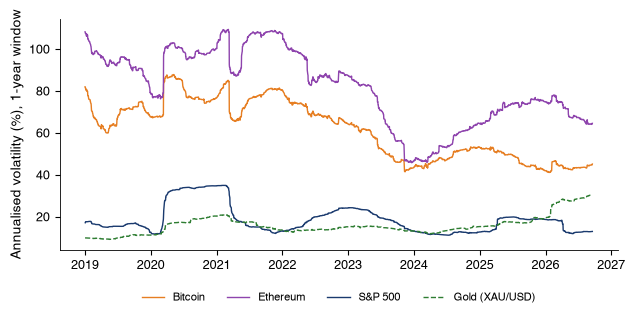

   saved ch16_rolling_vol
{'BTC': {'last': np.float64(45.08038507447969), 'min': np.float64(41.05212934873849), 'max': np.float64(87.77537444424225), 'min_date': '2026-01-19'}, 'ETH': {'last': np.float64(64.49569028563712), 'min': np.float64(45.7117162746907), 'max': np.float64(109.32164328592238), 'min_date': '2023-12-20'}, 'SPX': {'last': np.float64(12.902675341021537), 'min': np.float64(11.10037329316607), 'max': np.float64(34.910212692846976), 'min_date': '2024-07-09'}, 'GOLD': {'last': np.float64(30.31229786348122), 'min': np.float64(9.120586866740108), 'max': np.float64(30.31229786348122), 'min_date': '2019-05-15'}, 'btc_eth_ratio_last': np.float64(1.430681884794914), 'btc_spx_ratio_last': np.float64(3.4938788958872284)}


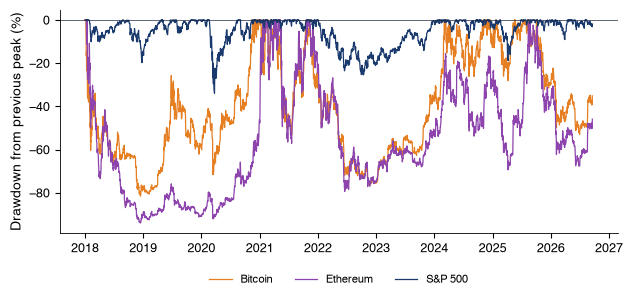

   saved ch16_drawdowns
{'BTC': {'min': np.float64(-81.5327115591944), 'min_date': '2018-12-15', 'last': np.float64(-35.15044383776625), 'share_below50': np.float64(36.380772855796415)}, 'ETH': {'min': np.float64(-93.96254040497699), 'min_date': '2018-12-14', 'last': np.float64(-45.94993411408358), 'share_below50': np.float64(61.262959472196044)}, 'SPX': {'min': np.float64(-33.9249600261347), 'min_date': '2020-03-23', 'last': np.float64(-1.903963229904937), 'share_below50': np.float64(0.0)}}


,N,start,ppy,ann_mean,ann_vol,skew,kurt,acf1,acf1_abs,var1,es2_5,min,min_date,mdd,mdd_date,hill_left,share5sd,var1_simple,es2_5_simple,min_simple
BTC,3182,2018-01-02,365.364822,20.4265,64.121262,-0.945702,14.833063,-0.046503,0.167694,10.223854,10.287778,-46.473021,2020-03-12,-81.532712,2018-12-15,2.72793,0.157134,9.718583,9.675489,-37.169541
ETH,3182,2018-01-02,365.364822,13.98315,84.337038,-0.824251,11.060023,-0.046054,0.155464,13.488352,13.684192,-55.073172,2020-03-12,-93.96254,2018-12-14,2.668015,0.125707,12.618231,12.647047,-42.34722
SOL,2351,2020-04-12,365.405426,77.345701,117.063048,-0.218955,7.88839,-0.041977,0.276674,14.46206,17.144676,-54.958202,2022-11-09,-96.272497,2022-12-29,2.848669,0.255211,13.464946,15.479812,-42.280899
DOGE,3182,2018-01-02,365.364822,26.220821,123.921147,4.876032,106.366343,0.027021,0.370681,13.791233,16.350159,-51.511165,2021-01-30,-92.258478,2022-06-18,2.832624,0.408548,12.882493,14.845292,-40.256611
SPX,2189,2018-01-03,251.425236,11.98057,19.187759,-0.645527,14.922445,-0.144612,0.357301,3.429764,3.83186,-12.765218,2020-03-16,-33.92496,2020-03-23,2.869843,0.411147,3.371614,3.743879,-11.984054
GOLD,2269,2018-01-02,260.531987,13.88689,17.205721,-0.548312,10.255483,-0.021102,0.125691,2.998658,3.181783,-11.140951,2026-01-30,-27.700612,2026-07-16,2.746899,0.264434,2.954144,3.121675,-10.542766


In [7]:
t = stylised_table()
print(fig_rolling_vol())
print(fig_drawdowns())
t.astype(float, errors='ignore').round(3)

![ch16_rolling_vol](./ch16_rolling_vol.png)

Output: `ch16_rolling_vol.pdf`

![ch16_drawdowns](./ch16_drawdowns.png)

Output: `ch16_drawdowns.pdf`